# Ideal closed cylindrical pillbox — conformal FIT / SIBC validation

**Objective:** Validate the fundamental TM$_{010}$ resonance of a completely closed cylindrical vacuum cavity against analytical results. The surrounding conducting STL shell is **10 cm thick in the radial and axial directions** and is terminated by PEC at the outer computational boundaries. No beam pipes, wake calculation, CST, or direct FD frequency sweep are used.

Workflow: (1) construct and inspect the thick-walled STL, (2) examine the actual WAKIS conformal grid and material mask, (3) PEC grid-convergence sweep, (4) choose a fixed grid, (5) SIBC conductivity sweep and analytical comparison.

**Important:** The SIBC treatment is a *first-order perturbation around PEC eigenmodes*, so a standard lossless `solve_eigenmodes()` is used for PEC only. We reuse the same field eigenvector for the SIBC conductivity sweep. The analytic $Q$ and frequency-shift expressions use the good-conductor approximation; agreement at very low conductivity is not guaranteed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyvista as pv
from scipy.constants import c, mu_0, pi
from scipy.special import jn_zeros
from wakis import GridFIT3D, SolverFIT3D
from wakis.solverFIT3D_FD import SolverFIT3D_FD
from IPython.display import display

# ---- Physical geometry [m] ----
RADIUS = 0.21  # vacuum radius a
LENGTH = 0.1  # vacuum length L
WALL_THICKNESS = 0.05  # radial AND axial thickness
N_THETA = 400  # STL facets around cylinder

# A small vacuum strip outside the solid shell remains before the outer PEC box.
# Exterior modes will therefore exist mathematically: target mode by field shape.
OUTER_PADDING = 0.0

# PEC grid convergence; increase the last value for tighter convergence.
GRID_SWEEP = [18, 24, 30, 36, 42, 48, 54]
GRID_Z_FACTOR = 0.90  # Nz ~ GRID_Z_FACTOR * Nx*(outer_z_span/outer_x_span)
SELECT_NX = 54  # one of GRID_SWEEP; fixed grid for the conductivity sweep
ETA = 0.2
N_MODES = 6
SIGMA_VALUES = np.geomspace(1e3, 1e8, 9)
MU_R_WALL = 1.0

OUTDIR = Path.cwd() / "ideal_pillbox_results"
OUTDIR.mkdir(exist_ok=True)
SHELL_PATH = OUTDIR / "ideal_closed_pillbox_shell_10cm.stl"

CAVITY_PATH = OUTDIR / "ideal_pillbox_vacuum.stl"


CHI01 = float(jn_zeros(0, 1)[0])
f_analytic = CHI01 * c / (2 * pi * RADIUS)
omega_analytic = 2 * pi * f_analytic
G_analytic = (RADIUS * LENGTH / (2 * (RADIUS + LENGTH))) * omega_analytic * mu_0
Q_norm_analytic = G_analytic * np.sqrt(2 / (omega_analytic * mu_0))
print(f"Analytical TM010 frequency: {f_analytic / 1e6:.6f} MHz")
print(f"Analytical geometry factor G: {G_analytic:.6f} Ohm")
print(f"Analytical Q/sqrt(sigma): {Q_norm_analytic:.7g}")

Analytical TM010 frequency: 546.392990 MHz
Analytical geometry factor G: 146.124304 Ohm
Analytical Q/sqrt(sigma): 3.146227


## 1. Generate a watertight 10 cm thick metal shell

The shell is the material between **two closed concentric cylinders**: the *inner* vacuum boundary $r=a$, $|z|=L/2$, and the *outer* cylinder $r=a+t$, $|z|=L/2+t$. The inner surface has opposite orientation. Both surfaces form the boundary of one closed metallic volume, including the end caps. The separate inner and outer surface components are intentional.

We check actual point-in-solid classification at the center of the cavity, inside the metal, and outside the shell before invoking WAKIS.

In [2]:
def triangulated_closed_cylinder(radius, zlow, zhigh, resolution, invert=False):
    theta = 2 * np.pi * np.arange(resolution) / resolution
    xy = np.c_[radius * np.cos(theta), radius * np.sin(theta)]
    points = np.vstack(
        [
            np.c_[xy, np.full(resolution, zlow)],
            np.c_[xy, np.full(resolution, zhigh)],
            [[0.0, 0.0, zlow], [0.0, 0.0, zhigh]],
        ]
    )
    lower_center, upper_center = 2 * resolution, 2 * resolution + 1
    triangles = []
    for i in range(resolution):
        j = (i + 1) % resolution
        triangles.extend(
            [
                (i, j, resolution + j),
                (i, resolution + j, resolution + i),
                (lower_center, j, i),
                (upper_center, resolution + i, resolution + j),
            ]
        )
    triangles = np.asarray(triangles, dtype=np.int64)
    if invert:
        triangles = triangles[:, [0, 2, 1]]
    faces = np.c_[np.full(len(triangles), 3), triangles].ravel()
    return pv.PolyData(points, faces)


inner = triangulated_closed_cylinder(
    RADIUS, -LENGTH / 2, LENGTH / 2, N_THETA, invert=True
)
outer = triangulated_closed_cylinder(
    RADIUS + WALL_THICKNESS,
    -LENGTH / 2 - WALL_THICKNESS,
    LENGTH / 2 + WALL_THICKNESS,
    N_THETA,
)

# Two components of a single shell surface, preserving their orientation.
shell = outer.merge(inner, merge_points=False).triangulate().clean()
print("STL triangles:", shell.n_cells, "| open edges:", shell.n_open_edges)
assert shell.n_open_edges == 0, "Shell must have no open edges"

probe_points = np.array(
    [
        [0, 0, 0],  # inside vacuum (not in metal)
        [RADIUS + WALL_THICKNESS / 2, 0, 0],  # cylindrical wall
        [0, 0, LENGTH / 2 + WALL_THICKNESS / 2],  # upper end cap
        [RADIUS + WALL_THICKNESS + 0.02, 0, 0],  # outside outer surface
    ]
)
probe_mesh = pv.PolyData(probe_points)
inside = np.asarray(
    probe_mesh.select_enclosed_points(shell, tolerance=1e-6, check_surface=True)[
        "SelectedPoints"
    ],
    dtype=bool,
)
print("Solid classification [cavity, sidewall, endcap, exterior]:", inside.astype(int))
assert np.array_equal(inside, [False, True, True, False]), (
    "Point classification failed: inspect the STL and its nested surface orientation."
)
shell.save(SHELL_PATH, binary=True)
print("Wrote:", SHELL_PATH.resolve())


cavity = triangulated_closed_cylinder(
    RADIUS,
    -LENGTH / 2,
    LENGTH / 2,
    N_THETA,
)

cavity.save(CAVITY_PATH)

p = pv.Plotter(notebook=True)
p.add_mesh(outer, color="slategray", opacity=0.20, label="outer metal boundary")
p.add_mesh(inner, color="dodgerblue", opacity=0.30, label="inner cavity boundary")
p.add_axes()
p.add_legend()
p.show()

STL triangles: 3200 | open edges: 0
Solid classification [cavity, sidewall, endcap, exterior]: [0 1 1 0]
Wrote: /home/hschreib/Documents/Wakis/WAKIS/notebooks/ideal_pillbox_results/ideal_closed_pillbox_shell_10cm.stl


/tmp/hschreib/ipykernel_44823/4186177931.py:44: PyVistaDeprecationWarning: This filter is deprecated. Use `select_interior_points` instead.
  inside = np.asarray(probe_mesh.select_enclosed_points(


Widget(value='<iframe src="http://localhost:38255/index.html?ui=P_0x7ff814381010_0&reconnect=auto" class="pyvi…

## 2. Build FIT grid and inspect with the existing WAKIS plotting methods

The solver uses **one STL material named `shell`**, set to `pec` or `sibc`. The background is normal/vacuum; outer Cartesian boundary planes are PEC. We check the grid's STL mask and use the built-in WAKIS `plot_solids()` and, when available, `plot_stl_mask_slice()` to confirm both the inner cylindrical boundary and the wall thickness.

The global computational box is just outside the outer shell. A small exterior vacuum strip remains; the physical TM$_{010}$ cavity mode is selected near its analytical frequency and checked using the electric-field distribution.

In [4]:
r_out = RADIUS + WALL_THICKNESS
z_out = LENGTH / 2 + WALL_THICKNESS
xmin = ymin = -r_out - OUTER_PADDING
xmax = ymax = r_out + OUTER_PADDING
zmin, zmax = -z_out - OUTER_PADDING, z_out + OUTER_PADDING


def mesh_shape(nxy):
    # Nearly equal cubic cell sizes (nx=ny, nz proportional to box length).
    nz = max(8, int(round(nxy * (zmax - zmin) / (xmax - xmin) * GRID_Z_FACTOR)))
    return nxy, nxy, nz


def make_solver(nxy, kind="pec", sigma=1e6, geometry_mode="conformal"):
    nx, ny, nz = mesh_shape(nxy)

    shell_material = (
        [np.inf, 1.0, 0.0] if kind == "pec" else [1.0, MU_R_WALL, float(sigma)]
    )

    grid = GridFIT3D(
        xmin=xmin,
        xmax=xmax,
        ymin=ymin,
        ymax=ymax,
        zmin=zmin,
        zmax=zmax,
        Nx=nx,
        Ny=ny,
        Nz=nz,
        stl_solids={
            "cavity": str(CAVITY_PATH),
            "shell": str(SHELL_PATH),
        },
        stl_materials={
            "cavity": [1.0, 1.0, 0.0],
            "shell": shell_material,
        },
        stl_material_types={
            "cavity": "normal",
            "shell": kind,
        },
        geometry_mode=geometry_mode,
        stl_method="interior_points",
        # Everything outside the STL volumes is PEC
        bg_material_type="pec",
        conformal_pec_snap_fraction=ETA,
        verbose=0,
    )

    solver = SolverFIT3D_FD(
        grid=grid,
        bg="pec",
        use_stl=True,
        use_sibc=False,
        bc_low=["PEC"] * 3,
        bc_high=["PEC"] * 3,
        verbose=0,
    )

    return grid, solver


preview_nxy = GRID_SWEEP[2]
grid_preview, solver_preview = make_solver(preview_nxy, kind="pec")

grid_preview.plot_solids(
    opacity=0.2,
    bounding_box=True,
    show_grid=False,
)

# # Native WAKIS material-mask slice, if present in this development branch.
# if hasattr(grid_preview, 'plot_stl_mask_slice'):
# # Longitudinal slice through the cylinder axis
#     grid_preview.plot_stl_mask_slice(
#         stl_solid="shell",
#         plane="ZX",
#         position=0.0,  # y = 0
#         add_stl=True,
#         stl_opacity=0.12,
#         show_grid=True,
#         bounding_box=True,
#     )

#     # Transverse slice through the center
#     grid_preview.plot_stl_mask_slice(
#         stl_solid="shell",
#         plane="XY",
#         position=0.0,  # z = 0
#         add_stl=True,
#         stl_opacity=0.12,
#         show_grid=True,
#         bounding_box=True,
#     )
# else:
#     print('plot_stl_mask_slice is not available in this WAKIS version.')

grid_preview.plot_stl_mask_slice("shell", plane="Xy", position=0.0)

Generating grid with 9000 mesh cells...
Initializing Electromagnetic solver...


Widget(value='<iframe src="http://localhost:38255/index.html?ui=P_0x7ff7baa756d0_3&reconnect=auto" class="pyvi…

2026-11-04 13:19:14.211 ( 143.826s) [    7FF90756F740]          vtkmSlice.cxx:327   WARN| vtkmSlice (0x55c1f3dbe460): Viskores failed with message: vtkmSlice only generates triangles in the output.
Falling back to the default VTK implementation.
2026-11-04 13:19:14.220 ( 143.835s) [    7FF90756F740]          vtkmSlice.cxx:327   WARN| vtkmSlice (0x55c1f4298060): Viskores failed with message: Input dataset not supported by vtkmSlice.
Falling back to the default VTK implementation.
2026-11-04 13:19:14.228 ( 143.844s) [    7FF90756F740]          vtkmSlice.cxx:327   WARN| vtkmSlice (0x55c1f3de1360): Viskores failed with message: vtkmSlice only generates triangles in the output.
Falling back to the default VTK implementation.
2026-11-04 13:19:14.232 ( 143.848s) [    7FF90756F740]          vtkmSlice.cxx:327   WARN| vtkmSlice (0x55c1f425ee10): Viskores failed with message: Input dataset not supported by vtkmSlice.
Falling back to the default VTK implementation.


Widget(value='<iframe src="http://localhost:38255/index.html?ui=P_0x7ff7baa76210_4&reconnect=auto" class="pyvi…

Initializing Electromagnetic solver...


2026-11-04 11:00:09.206 (  16.349s) [    7F0EFA2E7740]          vtkmSlice.cxx:327   WARN| vtkmSlice (0x556bc0762be0): Viskores failed with message: Input dataset not supported by vtkmSlice.
Falling back to the default VTK implementation.
2026-11-04 11:00:09.212 (  16.355s) [    7F0EFA2E7740]          vtkmSlice.cxx:327   WARN| vtkmSlice (0x556bc0bd8e70): Viskores failed with message: Input dataset not supported by vtkmSlice.
Falling back to the default VTK implementation.


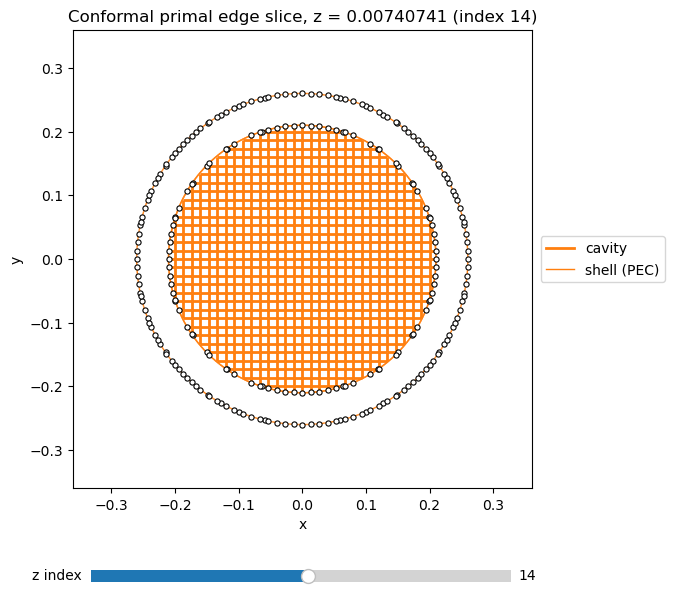

2026-11-04 11:00:09.448 (  16.591s) [    7F0EFA2E7740]          vtkmSlice.cxx:327   WARN| vtkmSlice (0x556bc0d53b30): Viskores failed with message: Input dataset not supported by vtkmSlice.
Falling back to the default VTK implementation.
2026-11-04 11:00:09.451 (  16.594s) [    7F0EFA2E7740]          vtkmSlice.cxx:327   WARN| vtkmSlice (0x556bc32b99b0): Viskores failed with message: Input dataset not supported by vtkmSlice.
Falling back to the default VTK implementation.


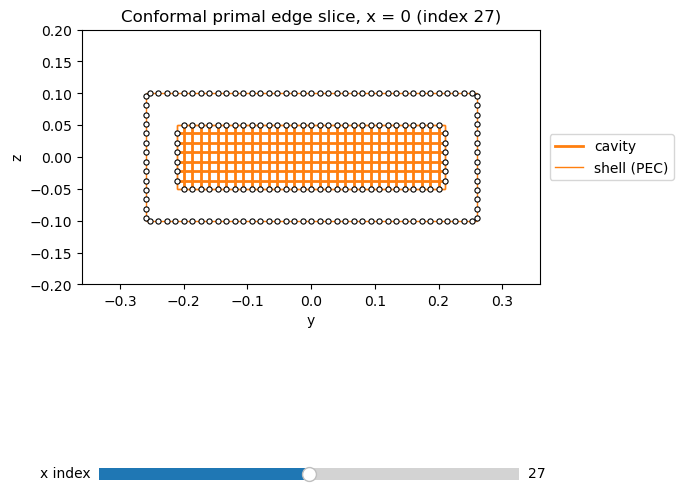

In [4]:
import matplotlib.pyplot as plt

# Temporary conformal solver for geometry diagnostics
preview_solver = SolverFIT3D(
    grid=grid_preview,
    use_stl=True,
    use_sibc=False,
    bc_low=["PEC"] * 3,
    bc_high=["PEC"] * 3,
    verbose=0,
    bg="PEC",
)

# Conformal edge-intersection diagnostics
for normal in ("z", "x"):
    preview_solver.plot_conformal_primal_edge_slice(
        normal=normal,
        show_full_grid=False,
        show_stl=True,
        show_intersection_marker=True,
    )
    plt.show()

del preview_solver

In [6]:
print(11.02 / 6.20)
print(16 / 9)

1.7774193548387096
1.7777777777777777


## 3. PEC grid-convergence sweep

For each grid, solve the **lossless** generalized eigenvalue problem near the analytical TM$_{010}$ frequency. Record the closest eigenfrequency and visualize the $E_z$ field for the selected mode. Modes should be identified not just by frequency, but also by the dominant longitudinal electric field in the *inner* cylinder (we report this fraction). Unlike a true convergence guarantee, this is a numerical heuristic; check the plots for spurious/exterior modes.

If the last mesh is still not sufficiently accurate, extend `GRID_SWEEP` to finer values before running the SIBC sweep.

In [16]:
def extract_mode_fields(solver, mode):
    E = np.zeros(3 * solver.N, dtype=complex)
    E[solver.free_E_idx] = np.asarray(mode, dtype=complex)
    return [
        E[j * solver.N : (j + 1) * solver.N].reshape(
            (solver.Nx, solver.Ny, solver.Nz), order="F"
        )
        for j in range(3)
    ]


def cavity_field_score(solver, mode):
    Ex, Ey, Ez = extract_mode_fields(solver, mode)
    x = xmin + (np.arange(solver.Nx) + 0.5) * (xmax - xmin) / solver.Nx
    y = ymin + (np.arange(solver.Ny) + 0.5) * (ymax - ymin) / solver.Ny
    z = zmin + (np.arange(solver.Nz) + 0.5) * (zmax - zmin) / solver.Nz
    mask = (x[:, None, None] ** 2 + y[None, :, None] ** 2 < (RADIUS * 0.95) ** 2) & (
        np.abs(z[None, None, :]) < 0.45 * LENGTH
    )
    e2 = np.abs(Ex) ** 2 + np.abs(Ey) ** 2 + np.abs(Ez) ** 2
    longitudinal_fraction = np.sum(np.abs(Ez[mask]) ** 2) / (np.sum(e2[mask]) + 1e-30)
    interior_fraction = np.sum(e2[mask]) / (np.sum(e2) + 1e-30)
    return float(longitudinal_fraction), float(interior_fraction)


pec_rows, pec_cache = [], {}
for nxy in GRID_SWEEP:
    print(f"\nPEC eigenmode sweep: Nx=Ny={nxy}, Nz={mesh_shape(nxy)[2]}", flush=True)
    grid, solver = make_solver(nxy, "pec")
    freqs, modes, eigenvalues = solver.solve_eigenmodes(
        n_modes=N_MODES, target_frequency=f_analytic
    )
    # Prefer close-to-analytic, Ez-polarized, cavity-localized modes.
    scores = [cavity_field_score(solver, modes[:, i]) for i in range(len(freqs))]
    candidates = [
        i
        for i, (longfrac, intfrac) in enumerate(scores)
        if longfrac > 0.65 and intfrac > 0.55
    ]
    if not candidates:
        print(
            "WARNING: no strongly TM010-like interior mode identified; inspect frequencies/fields."
        )
        candidates = list(range(len(freqs)))
    chosen = min(candidates, key=lambda i: abs(freqs[i] - f_analytic))
    f_num = float(freqs[chosen])
    err = (f_num / f_analytic - 1) * 100
    print(
        f"  TM010 candidate: mode {chosen}, f={f_num / 1e6:.7f} MHz, error={err:.4f}%"
    )
    print(f"  longitudinal / interior field fractions = {scores[chosen]}")
    pec_rows.append(
        dict(
            Nx=nxy,
            Ny=nxy,
            Nz=solver.Nz,
            f_PEC_hz=f_num,
            rel_error_pct=err,
            mode_index=chosen,
            E_longitudinal_fraction=scores[chosen][0],
            E_inside_fraction=scores[chosen][1],
        )
    )
    pec_cache[nxy] = (solver, f_num, np.asarray(modes[:, chosen], complex))
    del grid
pec_results = pd.DataFrame(pec_rows)
display(pec_results)
pec_results.to_csv(OUTDIR / "pec_grid_convergence.csv", index=False)


PEC eigenmode sweep: Nx=Ny=18, Nz=9
Generating grid with 2916 mesh cells...
Initializing Electromagnetic solver...
  TM010 candidate: mode 4, f=566.7725044 MHz, error=3.7298%
  longitudinal / interior field fractions = (0.9990049422648769, 0.9974521111851843)

PEC eigenmode sweep: Nx=Ny=24, Nz=12
Generating grid with 6912 mesh cells...


/home/hschreib/Documents/Wakis/WAKIS/wakis/gridFIT3D.py:4459: UserWarning: Conformal geometry diagnostics:
464 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
  self._warn_interface_diagnostics()


Initializing Electromagnetic solver...
  TM010 candidate: mode 5, f=552.1174219 MHz, error=1.0477%
  longitudinal / interior field fractions = (0.9998294651627124, 0.8007418681948604)

PEC eigenmode sweep: Nx=Ny=30, Nz=15
Generating grid with 13500 mesh cells...


/home/hschreib/Documents/Wakis/WAKIS/wakis/gridFIT3D.py:4459: UserWarning: Conformal geometry diagnostics:
208 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
  self._warn_interface_diagnostics()


Initializing Electromagnetic solver...
  TM010 candidate: mode 5, f=546.1427383 MHz, error=-0.0458%
  longitudinal / interior field fractions = (0.9999452409622656, 0.9120696869694991)

PEC eigenmode sweep: Nx=Ny=36, Nz=18
Generating grid with 23328 mesh cells...


/home/hschreib/Documents/Wakis/WAKIS/wakis/gridFIT3D.py:4459: UserWarning: Conformal geometry diagnostics:
96 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
  self._warn_interface_diagnostics()


... (4 outputs left out)

Initializing Electromagnetic solver...
  TM010 candidate: mode 3, f=546.7680490 MHz, error=0.0686%
  longitudinal / interior field fractions = (0.9999935988858755, 0.9987902537460378)

PEC eigenmode sweep: Nx=Ny=54, Nz=27
Generating grid with 78732 mesh cells...


/home/hschreib/Documents/Wakis/WAKIS/wakis/gridFIT3D.py:4459: UserWarning: Conformal geometry diagnostics:
552 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
  self._warn_interface_diagnostics()


Initializing Electromagnetic solver...
  TM010 candidate: mode 3, f=546.0387084 MHz, error=-0.0648%
  longitudinal / interior field fractions = (0.9999908935836905, 0.9988667427683671)


,Nx,Ny,Nz,f_PEC_hz,rel_error_pct,mode_index,E_longitudinal_fraction,E_inside_fraction
0,18,18,9,5.667725e+08,3.729827,4,0.999005,0.997452
1,24,24,12,5.521174e+08,1.047677,5,0.999829,0.800742
2,30,30,15,5.461427e+08,-0.045801,5,0.999945,0.912070
3,36,36,18,5.451622e+08,-0.225257,3,0.999989,0.968229
4,42,42,21,5.472577e+08,0.158249,3,0.999996,0.998864
5,48,48,24,5.467680e+08,0.068643,3,0.999994,0.998790
6,54,54,27,5.460387e+08,-0.064840,3,0.999991,0.998867


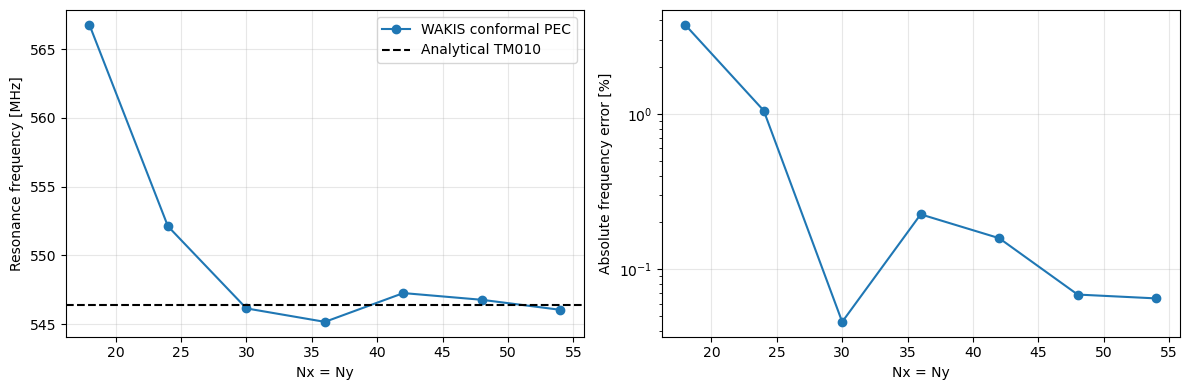

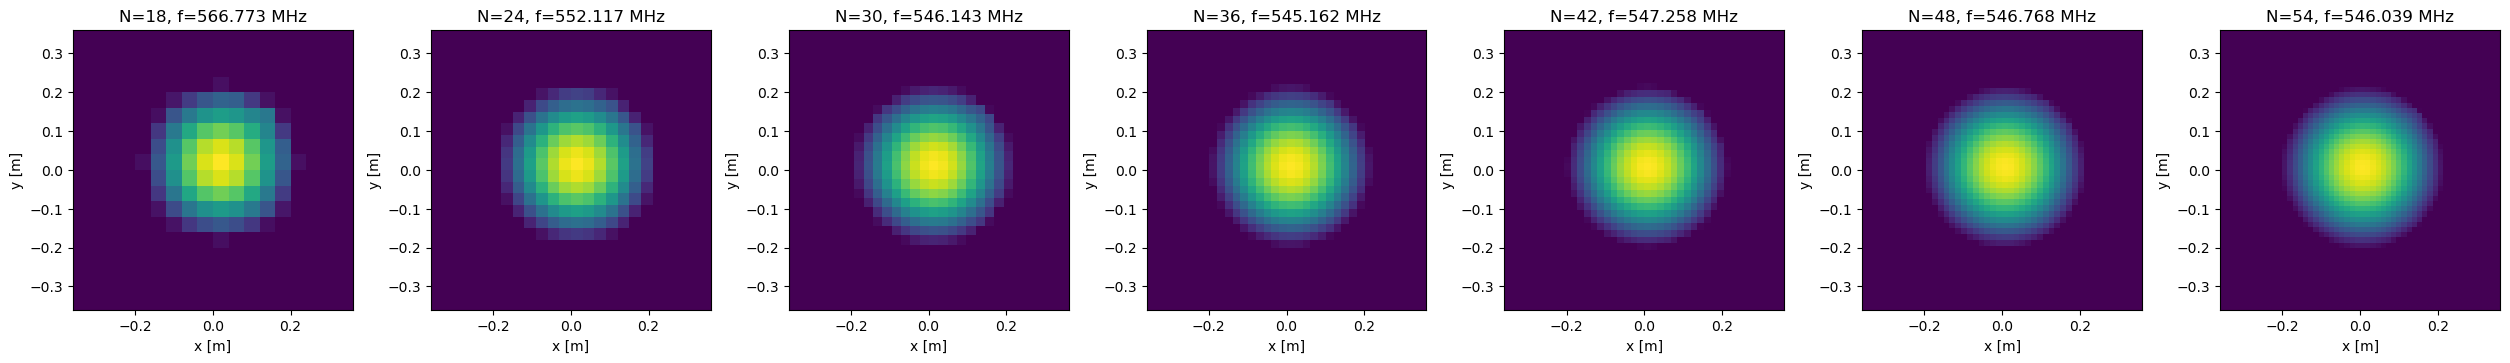

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(
    pec_results.Nx, pec_results.f_PEC_hz / 1e6, "o-", label="WAKIS conformal PEC"
)
axs[0].axhline(f_analytic / 1e6, ls="--", color="black", label="Analytical TM010")
axs[0].set_ylabel("Resonance frequency [MHz]")
axs[1].plot(pec_results.Nx, np.abs(pec_results.rel_error_pct), "o-")
axs[1].set_yscale("log")
axs[1].set_ylabel("Absolute frequency error [%]")
for ax in axs:
    ax.set_xlabel("Nx = Ny")
    ax.grid(alpha=0.3)
axs[0].legend()
plt.tight_layout()
plt.show()

# Show Ez transverse and axial cuts for each grid, with actual sample axes.
fig, axs = plt.subplots(1, len(GRID_SWEEP), figsize=(3.6 * len(GRID_SWEEP), 3.5))
axs = np.atleast_1d(axs)
for ax, nxy in zip(axs, GRID_SWEEP):
    sol, freq, vec = pec_cache[nxy]
    _, _, Ez = extract_mode_fields(sol, vec)
    image = np.abs(Ez[:, :, sol.Nz // 2]).T
    ax.imshow(image, origin="lower", extent=[xmin, xmax, ymin, ymax], aspect="equal")
    ax.set_title(f"N={nxy}, f={freq / 1e6:.3f} MHz")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
plt.tight_layout()
plt.show()

In [28]:
# ============================================================
# PEC eigenmode convergence: Legacy FIT (non-conformal)
# ============================================================

legacy_rows = []
legacy_cache = {}

for nxy in GRID_SWEEP:
    print(
        f"\nLegacy PEC eigenmode sweep: Nx=Ny={nxy}, Nz={mesh_shape(nxy)[2]}",
        flush=True,
    )

    grid, solver = make_solver(
        nxy,
        kind="pec",
        geometry_mode="legacy",
    )

    freqs, modes, eigenvalues = solver.solve_eigenmodes(
        n_modes=N_MODES,
        target_frequency=f_analytic,
    )

    # Same mode selection as conformal FIT
    scores = [cavity_field_score(solver, modes[:, i]) for i in range(len(freqs))]

    candidates = [
        i
        for i, (longfrac, intfrac) in enumerate(scores)
        if longfrac > 0.65 and intfrac > 0.55
    ]

    if not candidates:
        print(
            "WARNING: no strongly TM010-like interior mode "
            "identified; inspect frequencies/fields."
        )
        candidates = list(range(len(freqs)))

    chosen = min(
        candidates,
        key=lambda i: abs(freqs[i] - f_analytic),
    )

    f_num = float(freqs[chosen])
    err = (f_num / f_analytic - 1) * 100

    print(
        f"  TM010 candidate: mode {chosen}, f={f_num / 1e6:.7f} MHz, error={err:.4f}%"
    )

    print(
        "  longitudinal / interior field fractions =",
        scores[chosen],
    )

    legacy_rows.append(
        dict(
            Nx=nxy,
            Ny=nxy,
            Nz=solver.Nz,
            f_PEC_hz=f_num,
            rel_error_pct=err,
            mode_index=chosen,
            E_longitudinal_fraction=scores[chosen][0],
            E_inside_fraction=scores[chosen][1],
        )
    )

    legacy_cache[nxy] = (
        solver,
        f_num,
        np.asarray(modes[:, chosen], complex),
    )

    del grid

legacy_results = pd.DataFrame(legacy_rows)

display(legacy_results)

legacy_results.to_csv(
    OUTDIR / "pec_legacy_grid_convergence.csv",
    index=False,
)


Legacy PEC eigenmode sweep: Nx=Ny=18, Nz=9
Generating grid with 2916 mesh cells...
Initializing Electromagnetic solver...
  TM010 candidate: mode 1, f=608.6168444 MHz, error=11.3881%
  longitudinal / interior field fractions = (0.8279695442822885, 0.9999999999999999)

Legacy PEC eigenmode sweep: Nx=Ny=24, Nz=12
Generating grid with 6912 mesh cells...
Initializing Electromagnetic solver...
  TM010 candidate: mode 2, f=474.6158006 MHz, error=-13.1366%
  longitudinal / interior field fractions = (0.9600274510327398, 1.0000000000000002)

Legacy PEC eigenmode sweep: Nx=Ny=30, Nz=15
Generating grid with 13500 mesh cells...
Initializing Electromagnetic solver...
  TM010 candidate: mode 3, f=485.1764273 MHz, error=-11.2038%
  longitudinal / interior field fractions = (0.9751986430402868, 0.9999999999999998)

Legacy PEC eigenmode sweep: Nx=Ny=36, Nz=18
Generating grid with 23328 mesh cells...
Initializing Electromagnetic solver...
  TM010 candidate: mode 3, f=499.1371234 MHz, error=-8.6487%
  

,Nx,Ny,Nz,f_PEC_hz,rel_error_pct,mode_index,E_longitudinal_fraction,E_inside_fraction
0,18,18,9,6.086168e+08,11.388114,1,0.827970,1.00000
1,24,24,12,4.746158e+08,-13.136550,2,0.960027,1.00000
2,30,30,15,4.851764e+08,-11.203761,3,0.975199,1.00000
3,36,36,18,4.991371e+08,-8.648696,3,0.982436,1.00000
4,42,42,21,5.053934e+08,-7.503684,4,0.987134,1.00000
5,48,48,24,5.165499e+08,-5.461829,4,0.989878,1.00000
6,54,54,27,5.082233e+08,-6.985762,5,0.992450,0.99989


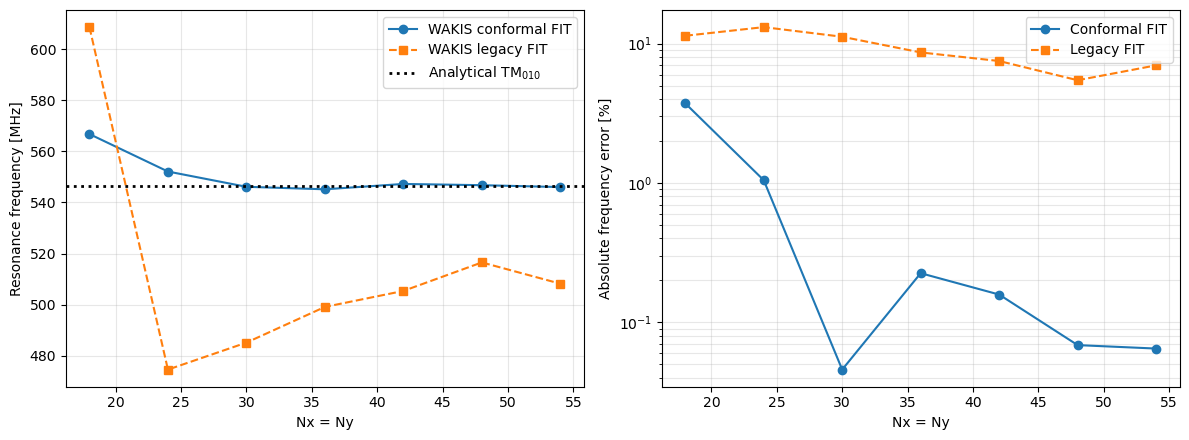

In [29]:
# ============================================================
# PEC convergence: conformal vs legacy
# ============================================================

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

# Resonance frequency
axs[0].plot(
    pec_results.Nx,
    pec_results.f_PEC_hz / 1e6,
    "o-",
    label="WAKIS conformal FIT",
)

axs[0].plot(
    legacy_results.Nx,
    legacy_results.f_PEC_hz / 1e6,
    "s--",
    label="WAKIS legacy FIT",
)

axs[0].axhline(
    f_analytic / 1e6,
    linestyle=":",
    color="black",
    linewidth=2,
    label=r"Analytical TM$_{010}$",
)

axs[0].set_ylabel("Resonance frequency [MHz]")

# Absolute relative frequency error
axs[1].plot(
    pec_results.Nx,
    np.abs(pec_results.rel_error_pct),
    "o-",
    label="Conformal FIT",
)

axs[1].plot(
    legacy_results.Nx,
    np.abs(legacy_results.rel_error_pct),
    "s--",
    label="Legacy FIT",
)

axs[1].set_yscale("log")
axs[1].set_ylabel("Absolute frequency error [%]")

for ax in axs:
    ax.set_xlabel("Nx = Ny")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

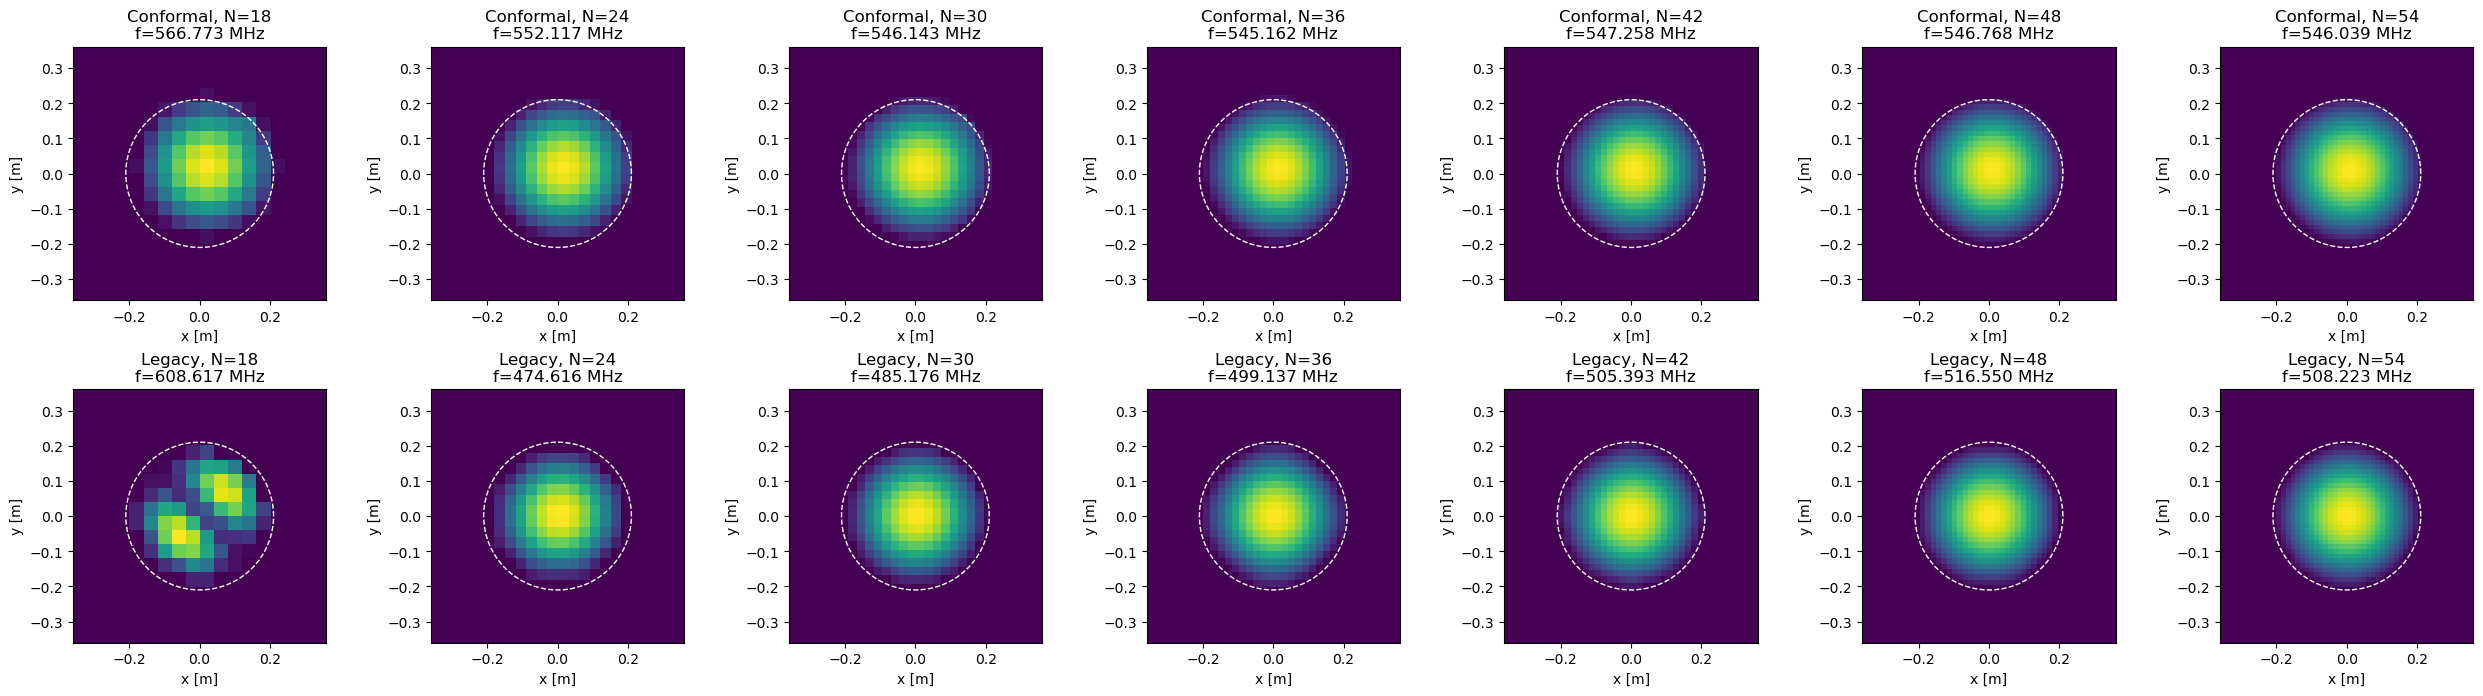

In [30]:
# ============================================================
# Ez field comparison: conformal vs legacy
# ============================================================

fig, axs = plt.subplots(
    2,
    len(GRID_SWEEP),
    figsize=(3.6 * len(GRID_SWEEP), 7),
    squeeze=False,
)

theta = np.linspace(0, 2 * np.pi, 400)

for col, nxy in enumerate(GRID_SWEEP):
    for row, (cache, method) in enumerate(
        [
            (pec_cache, "Conformal"),
            (legacy_cache, "Legacy"),
        ]
    ):
        sol, freq, vec = cache[nxy]

        _, _, Ez = extract_mode_fields(sol, vec)

        image = np.abs(Ez[:, :, sol.Nz // 2]).T

        ax = axs[row, col]

        ax.imshow(
            image,
            origin="lower",
            extent=[xmin, xmax, ymin, ymax],
            aspect="equal",
        )

        # Analytical cavity boundary
        ax.plot(
            RADIUS * np.cos(theta),
            RADIUS * np.sin(theta),
            "w--",
            linewidth=1,
        )

        ax.set_title(f"{method}, N={nxy}\nf={freq / 1e6:.3f} MHz")

        ax.set_xlabel("x [m]")
        ax.set_ylabel("y [m]")

plt.tight_layout()
plt.show()

In [31]:
comparison = pec_results[["Nx", "f_PEC_hz"]].merge(
    legacy_results[["Nx", "f_PEC_hz"]],
    on="Nx",
    suffixes=("_conformal", "_legacy"),
)

comparison["a_eff_conformal"] = CHI01 * c / (2 * np.pi * comparison.f_PEC_hz_conformal)

comparison["a_eff_legacy"] = CHI01 * c / (2 * np.pi * comparison.f_PEC_hz_legacy)

comparison["radius_error_legacy_pct"] = (comparison.a_eff_legacy / RADIUS - 1) * 100

display(comparison)

,Nx,f_PEC_hz_conformal,f_PEC_hz_legacy,a_eff_conformal,a_eff_legacy,radius_error_legacy_pct
0,18,5.667725e+08,6.086168e+08,0.202449,0.188530,-10.223814
1,24,5.521174e+08,4.746158e+08,0.207823,0.241759,15.123219
2,30,5.461427e+08,4.851764e+08,0.210096,0.236497,12.617382
3,36,5.451622e+08,4.991371e+08,0.210474,0.229882,9.467512
4,42,5.472577e+08,5.053934e+08,0.209668,0.227036,8.112414
5,48,5.467680e+08,5.165499e+08,0.209856,0.222132,5.777379
6,54,5.460387e+08,5.082233e+08,0.210136,0.225772,7.510422


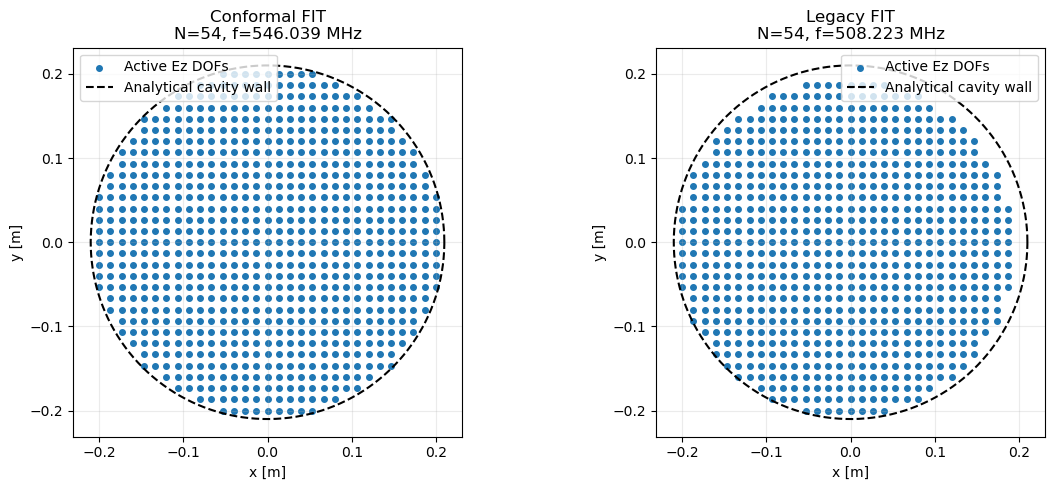

In [32]:
import numpy as np
import matplotlib.pyplot as plt

N_COMPARE = 54

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

theta = np.linspace(0, 2 * np.pi, 500)

for ax, (cache, name) in zip(
    axs,
    [
        (pec_cache, "Conformal FIT"),
        (legacy_cache, "Legacy FIT"),
    ],
):
    solver, f_mode, e = cache[N_COMPARE]

    # Active E DOFs (global flattened index)
    active = np.zeros(3 * solver.N, dtype=bool)
    active[np.asarray(solver.free_E_idx, dtype=int)] = True

    # Extract Ez DOF mask
    active_ez = active[2 * solver.N : 3 * solver.N].reshape(
        (solver.Nx, solver.Ny, solver.Nz),
        order="F",
    )

    # Primal x/y positions of z-directed electric edges
    x_ez = np.asarray(solver.grid.x[:-1])
    y_ez = np.asarray(solver.grid.y[:-1])

    # Select z-slice closest to cavity center
    iz = solver.Nz // 2

    X, Y = np.meshgrid(x_ez, y_ez, indexing="ij")

    # Plot active Ez DOFs
    mask = active_ez[:, :, iz]

    ax.scatter(
        X[mask],
        Y[mask],
        s=16,
        label="Active Ez DOFs",
    )

    # Analytical cavity boundary
    ax.plot(
        RADIUS * np.cos(theta),
        RADIUS * np.sin(theta),
        "k--",
        linewidth=1.5,
        label="Analytical cavity wall",
    )

    ax.set_title(f"{name}\nN={N_COMPARE}, f={f_mode / 1e6:.3f} MHz")

    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

In [33]:
for cache, name in [
    (pec_cache, "Conformal FIT"),
    (legacy_cache, "Legacy FIT"),
]:
    solver, f_mode, e = cache[N_COMPARE]

    active = np.zeros(3 * solver.N, dtype=bool)
    active[solver.free_E_idx] = True

    active_ez = active[2 * solver.N : 3 * solver.N].reshape(
        (solver.Nx, solver.Ny, solver.Nz),
        order="F",
    )

    x = np.asarray(solver.grid.x[:-1])
    y = np.asarray(solver.grid.y[:-1])

    X, Y = np.meshgrid(x, y, indexing="ij")
    r = np.sqrt(X**2 + Y**2)

    iz = solver.Nz // 2
    mask = active_ez[:, :, iz]

    radii = r[mask]

    outside = radii > RADIUS

    print(f"\n{name}")
    print(f"  Active Ez DOFs: {mask.sum()}")
    print(f"  Maximum active radius: {radii.max():.6f} m")
    print(f"  Analytical radius:     {RADIUS:.6f} m")
    print(f"  Active DOFs outside:   {outside.sum()}")
    print(f"  Fraction outside:      {100 * np.mean(outside):.2f}%")


Conformal FIT
  Active Ez DOFs: 761
  Maximum active radius: 0.207418 m
  Analytical radius:     0.210000 m
  Active DOFs outside:   0
  Fraction outside:      0.00%

Legacy FIT
  Active Ez DOFs: 716
  Maximum active radius: 0.208700 m
  Analytical radius:     0.210000 m
  Active DOFs outside:   0
  Fraction outside:      0.00%


## 4. Fixed-grid PEC and SIBC diagnostics

Use `SELECT_NX` to select a sufficiently converged mesh. Reuse its PEC eigenvector for the SIBC projection. Construct a new SIBC solver with identical geometry and verify identical active electrical DOFs and lossless FIT matrices. Count SIBC faces actually coupled to the curl operator.

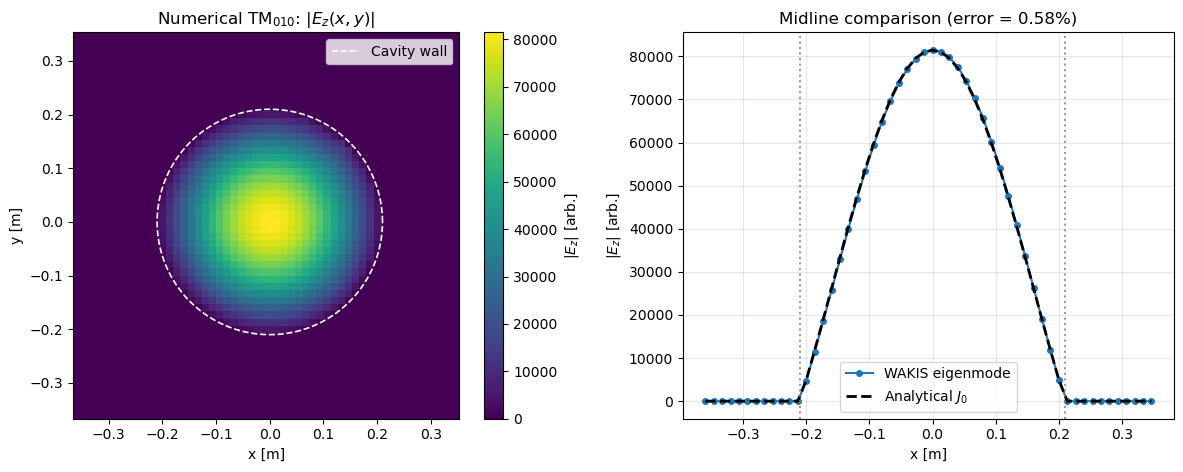

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0

Ex, Ey, Ez = extract_mode_fields(pec, e)

# Primal positions of z-directed electric FIT edges
x_ez = np.asarray(pec.grid.x[:-1])
y_ez = np.asarray(pec.grid.y[:-1])

iz = pec.Nz // 2
iy = int(np.argmin(np.abs(y_ez)))

Ez_xy = np.abs(Ez[:, :, iz])
Ez_line = Ez_xy[:, iy]

# Analytical TM010 profile along the sampled line
r_line = np.sqrt(x_ez**2 + y_ez[iy] ** 2)

phi = np.zeros_like(r_line)
inside = r_line <= RADIUS
phi[inside] = j0(CHI01 * r_line[inside] / RADIUS)

# Least-squares amplitude fit
amplitude = np.dot(phi, Ez_line) / np.dot(phi, phi)
Ez_analytic = amplitude * phi

shape_error = np.linalg.norm(Ez_line[inside] - Ez_analytic[inside]) / np.linalg.norm(
    Ez_analytic[inside]
)

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: XY field map
im = axs[0].pcolormesh(
    x_ez,
    y_ez,
    Ez_xy.T,
    shading="nearest",
    cmap="viridis",
)

theta = np.linspace(0, 2 * np.pi, 400)
axs[0].plot(
    RADIUS * np.cos(theta),
    RADIUS * np.sin(theta),
    "w--",
    linewidth=1.2,
    label="Cavity wall",
)

axs[0].set_aspect("equal")
axs[0].set_xlabel("x [m]")
axs[0].set_ylabel("y [m]")
axs[0].set_title(r"Numerical TM$_{010}$: $|E_z(x,y)|$")
axs[0].legend(loc="upper right")

fig.colorbar(im, ax=axs[0], label=r"$|E_z|$ [arb.]")

# Right: x-axis comparison
axs[1].plot(
    x_ez,
    Ez_line,
    "o-",
    markersize=4,
    label="WAKIS eigenmode",
)

axs[1].plot(
    x_ez,
    Ez_analytic,
    "k--",
    linewidth=2,
    label=r"Analytical $J_0$",
)

for wall in (-RADIUS, RADIUS):
    axs[1].axvline(wall, linestyle=":", color="gray", alpha=0.8)

axs[1].set_xlabel("x [m]")
axs[1].set_ylabel(r"$|E_z|$ [arb.]")
axs[1].set_title(f"Midline comparison (error = {100 * shape_error:.2f}%)")
axs[1].grid(alpha=0.3)
axs[1].legend()

plt.tight_layout()
plt.show()

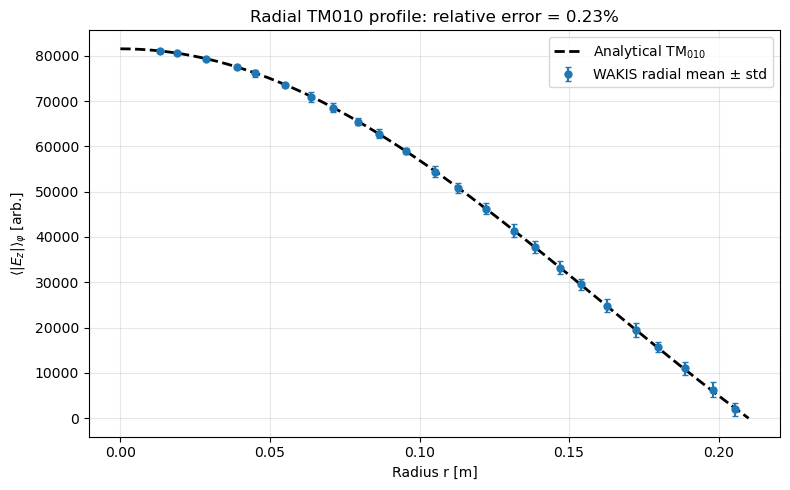

Radial bins used: 24
Total samples: 776
Relative radial shape error: 0.2290%


,r [m],Mean |Ez|,Std |Ez|,Points,Analytical |Ez|
0,0.013333,81033.040680,78.733295,4,81047.457747
1,0.018856,80560.061085,111.783182,4,80574.392910
2,0.028765,79305.459757,277.918702,12,79319.774974
3,0.038856,77518.845959,323.387996,8,77533.141756
4,0.045119,76136.643880,736.363622,16,76150.213368
5,0.054963,73628.120315,442.276567,16,73642.773358
6,0.063851,70946.363005,1146.992945,20,70958.516754
7,0.071001,68566.049237,1048.372605,20,68579.498385
8,0.079540,65447.663307,720.661412,20,65465.606124
9,0.086382,62751.204970,1017.411452,24,62757.591146


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import j0

# --------------------------------------------------
# 1. Radial distances of Ez DOFs
# --------------------------------------------------

X, Y = np.meshgrid(x_ez, y_ez, indexing="ij")

r = np.sqrt(X**2 + Y**2)
Ez_abs = np.abs(Ez[:, :, iz])

inside = r < RADIUS

r_samples = r[inside]
Ez_samples = Ez_abs[inside]

# --------------------------------------------------
# 2. Radial binning
# --------------------------------------------------

N_RADIAL_BINS = 25
MIN_POINTS_PER_BIN = 4

edges = np.linspace(0, RADIUS, N_RADIAL_BINS + 1)

r_mean = []
Ez_mean = []
Ez_std = []
n_points = []
phi_mean = []

for i in range(N_RADIAL_BINS):
    if i == N_RADIAL_BINS - 1:
        mask = (r_samples >= edges[i]) & (r_samples <= edges[i + 1])
    else:
        mask = (r_samples >= edges[i]) & (r_samples < edges[i + 1])

    n = np.count_nonzero(mask)

    if n < MIN_POINTS_PER_BIN:
        continue

    rr = r_samples[mask]
    zz = Ez_samples[mask]

    r_mean.append(rr.mean())
    Ez_mean.append(zz.mean())
    Ez_std.append(zz.std())
    n_points.append(n)

    # Average analytical values at the same DOF positions
    phi_mean.append(np.mean(j0(CHI01 * rr / RADIUS)))

r_mean = np.asarray(r_mean)
Ez_mean = np.asarray(Ez_mean)
Ez_std = np.asarray(Ez_std)
n_points = np.asarray(n_points)
phi_mean = np.asarray(phi_mean)

if len(r_mean) < 3:
    raise RuntimeError(
        "Too few radial bins. Reduce MIN_POINTS_PER_BIN or N_RADIAL_BINS."
    )

# --------------------------------------------------
# 3. Best-fit analytical amplitude
# --------------------------------------------------

amplitude_radial = np.dot(phi_mean, Ez_mean) / np.dot(phi_mean, phi_mean)

Ez_fit_bins = amplitude_radial * phi_mean

relative_radial_error = np.linalg.norm(Ez_mean - Ez_fit_bins) / np.linalg.norm(
    Ez_fit_bins
)

# Smooth analytical curve for visualization
r_smooth = np.linspace(0, RADIUS, 500)
Ez_smooth = amplitude_radial * j0(CHI01 * r_smooth / RADIUS)

# --------------------------------------------------
# 4. Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    r_mean,
    Ez_mean,
    yerr=Ez_std,
    fmt="o",
    capsize=2,
    markersize=5,
    label="WAKIS radial mean ± std",
)

ax.plot(
    r_smooth,
    Ez_smooth,
    "k--",
    linewidth=2,
    label=r"Analytical TM$_{010}$",
)

ax.set_xlabel("Radius r [m]")
ax.set_ylabel(r"$\langle |E_z| \rangle_\varphi$ [arb.]")
ax.set_title(
    f"Radial TM010 profile: relative error = {100 * relative_radial_error:.2f}%"
)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. Diagnostics
# --------------------------------------------------

print(f"Radial bins used: {len(r_mean)}")
print(f"Total samples: {n_points.sum()}")
print(f"Relative radial shape error: {100 * relative_radial_error:.4f}%")

radial_table = pd.DataFrame(
    {
        "r [m]": r_mean,
        "Mean |Ez|": Ez_mean,
        "Std |Ez|": Ez_std,
        "Points": n_points,
        "Analytical |Ez|": Ez_fit_bins,
    }
)

display(radial_table)

## 5. Conductivity sweep: first-order SIBC correction vs analytic TM$_{010}$

For fixed PEC mode $\mathbf e$, use the magnetic stiffness perturbation:

$$\delta K=\mathbf e^H C_\mathrm{red}^T\,\mathrm{diag}\!\left[M_\nu\left(\frac1{D_{Z_s}}-1\right)\right] C_\mathrm{red}\,\mathbf e,\qquad \delta\omega=\frac{\delta K}{2\omega_0\,\mathbf e^H M_\varepsilon\mathbf e}.$$

The numerical first-order results are $f_r=f_{\mathrm{PEC,num}}+\Re(\delta\omega)/(2\pi)$ and $Q=\omega_r/[2\Im(\delta\omega)]$ (matching our earlier WAKIS sign convention).

The analytical references use the *ideal geometry* $a,L$: $Q=\frac{aL}{a+L}\sqrt{\omega_{010}\mu_0\sigma/2}$ and $f_r\simeq f_{010}^{\rm PEC}\left(1-1/(2Q)\right)$; the latter applies only at high $Q$. For isolating the SIBC error from the PEC spatial error, an additional shift comparison uses the **numerical** PEC frequency plus the **analytical** perturbative shift.

In [20]:
C_red = sibc.C_red.tocsr()
mnu_diag = np.asarray(sibc.Mnu.diagonal())
Cn = float(np.vdot(e, pec.Meps @ e).real)
curl_e = C_red @ e
assert Cn > 0
sigma_original = np.array(sibc.sibc_sigma, copy=True)
rows = []
try:
    for sigma in SIGMA_VALUES:
        sibc.sibc_sigma[active_faces] = float(sigma)
        D = np.asarray(sibc._build_sibc_diagonal(omega0), dtype=complex)
        if D.ndim == 2:
            D = D.diagonal()
        delta_mnu = mnu_diag * (1 / D - 1)
        delta_K = np.vdot(curl_e, delta_mnu * curl_e)
        domega = delta_K / (2 * omega0 * Cn)
        if domega.imag <= 0:
            raise RuntimeError(
                f"Non-positive damping at sigma={sigma:g}: delta_omega={domega}"
            )
        f_sibc = f0 + domega.real / (2 * pi)
        Q_sibc = (2 * pi * f_sibc) / (2 * domega.imag)
        q_ref = Q_norm_analytic * np.sqrt(sigma)
        f_ref = f_analytic * (1 - 1 / (2 * q_ref))
        f_ref_numeric_baseline = f0 - f_analytic / (2 * q_ref)
        rows.append(
            dict(
                sigma=float(sigma),
                f_sibc_hz=float(f_sibc),
                Q_sibc=float(Q_sibc),
                Q_over_sqrt_sigma_sibc=float(Q_sibc / np.sqrt(sigma)),
                f_analytical_hz=float(f_ref),
                f_analytical_shift_on_numeric_PEC_hz=float(f_ref_numeric_baseline),
                Q_analytical=float(q_ref),
                Q_over_sqrt_sigma_analytical=float(Q_norm_analytic),
                Q_relative_error_pct=float((Q_sibc / q_ref - 1) * 100),
                delta_f_sibc_hz=float(f_sibc - f0),
                delta_f_analytical_hz=float(-f_analytic / (2 * q_ref)),
            )
        )
finally:
    sibc.sibc_sigma[:] = sigma_original

results = pd.DataFrame(rows)
display(results)
results.to_csv(OUTDIR / "sibc_conductivity_sweep.csv", index=False)

,sigma,f_sibc_hz,Q_sibc,Q_over_sqrt_sigma_sibc,f_analytical_hz,f_analytical_shift_on_numeric_PEC_hz,Q_analytical,Q_over_sqrt_sigma_analytical,Q_relative_error_pct,delta_f_sibc_hz,delta_f_analytical_hz
0,1.000000e+03,5.434740e+08,115.218072,3.643515,5.436471e+08,5.432928e+08,99.492428,3.146227,15.805870,-2.564755e+06,-2.745902e+06
1,4.216965e+03,5.447842e+08,226.690520,3.490867,5.450558e+08,5.447015e+08,204.310190,3.146227,10.954094,-1.254469e+06,-1.337165e+06
2,1.778279e+04,5.454271e+08,455.600667,3.416523,5.457418e+08,5.453876e+08,419.556089,3.146227,8.591123,-6.116239e+05,-6.511561e+05
3,7.498942e+04,5.457408e+08,925.680862,3.380347,5.460759e+08,5.457216e+08,861.568929,3.146227,7.441301,-2.979329e+05,-3.170919e+05
4,3.162278e+05,5.458936e+08,1891.009256,3.362743,5.462386e+08,5.458843e+08,1769.253358,3.146227,6.881767,-1.450947e+05,-1.544134e+05
5,1.333521e+06,5.459681e+08,3873.339648,3.354174,5.463178e+08,5.459635e+08,3633.206049,3.146227,6.609413,-7.065769e+04,-7.519433e+04
6,5.623413e+06,5.460043e+08,7944.107114,3.350002,5.463564e+08,5.460021e+08,7460.879547,3.146227,6.476818,-3.440815e+04,-3.661720e+04
7,2.371374e+07,5.460220e+08,16303.531215,3.347971,5.463752e+08,5.460209e+08,15321.102870,3.146227,6.412256,-1.675567e+04,-1.783139e+04
8,1.000000e+08,5.460305e+08,33469.818428,3.346982,5.463843e+08,5.460300e+08,31462.268176,3.146227,6.380819,-8.159469e+03,-8.683306e+03


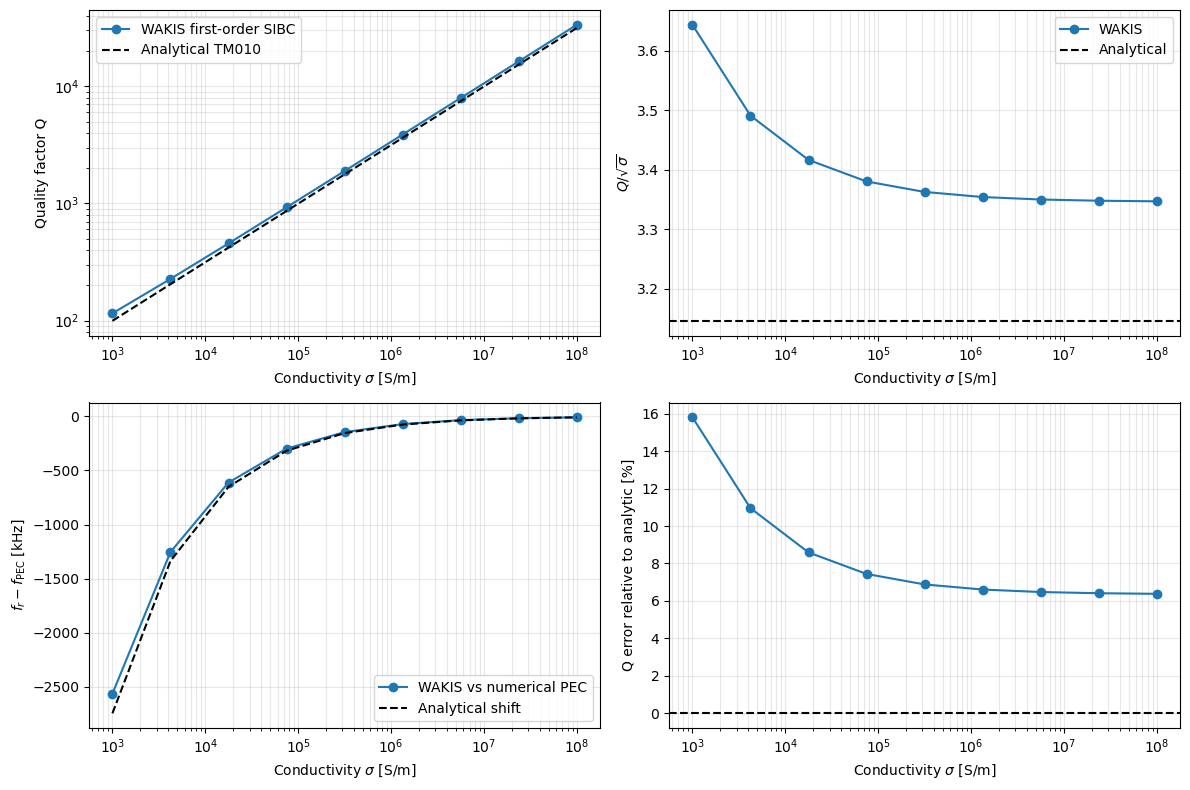

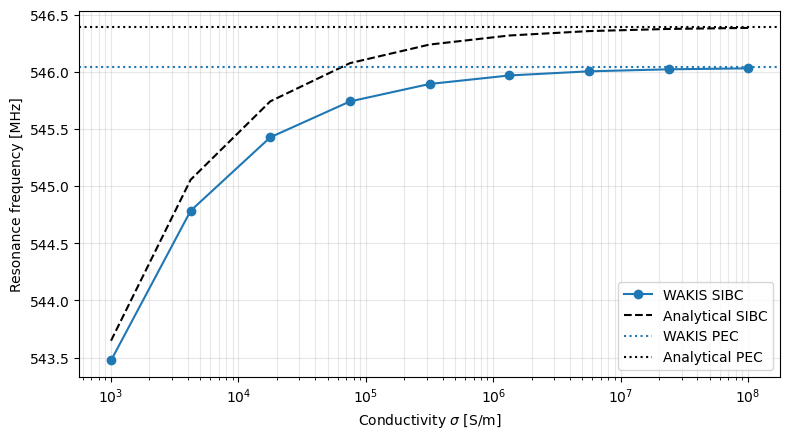

In [21]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs[0, 0].loglog(results.sigma, results.Q_sibc, "o-", label="WAKIS first-order SIBC")
axs[0, 0].loglog(results.sigma, results.Q_analytical, "k--", label="Analytical TM010")
axs[0, 0].set_ylabel("Quality factor Q")

axs[0, 1].semilogx(results.sigma, results.Q_over_sqrt_sigma_sibc, "o-", label="WAKIS")
axs[0, 1].axhline(Q_norm_analytic, ls="--", color="black", label="Analytical")
axs[0, 1].set_ylabel(r"$Q/\sqrt{\sigma}$")

axs[1, 0].semilogx(
    results.sigma, results.delta_f_sibc_hz / 1e3, "o-", label="WAKIS vs numerical PEC"
)
axs[1, 0].semilogx(
    results.sigma, results.delta_f_analytical_hz / 1e3, "k--", label="Analytical shift"
)
axs[1, 0].set_ylabel(r"$f_r-f_\mathrm{PEC}$ [kHz]")

axs[1, 1].semilogx(results.sigma, results.Q_relative_error_pct, "o-")
axs[1, 1].axhline(0, color="black", ls="--")
axs[1, 1].set_ylabel("Q error relative to analytic [%]")

for ax in axs.flat:
    ax.set_xlabel(r"Conductivity $\sigma$ [S/m]")
    ax.grid(alpha=0.3, which="both")
for ax in [axs[0, 0], axs[0, 1], axs[1, 0]]:
    ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(results.sigma, results.f_sibc_hz / 1e6, "o-", label="WAKIS SIBC")
ax.semilogx(
    results.sigma, results.f_analytical_hz / 1e6, "k--", label="Analytical SIBC"
)
ax.axhline(f0 / 1e6, label="WAKIS PEC", ls=":", color="tab:blue")
ax.axhline(f_analytic / 1e6, label="Analytical PEC", ls=":", color="black")
ax.set(xlabel=r"Conductivity $\sigma$ [S/m]", ylabel="Resonance frequency [MHz]")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

Total active SIBC DOFs: 4276
Total loss weight: 3.507464e+15
Q from decomposition: 3355.432700
Q/sqrt(sigma): 3.355433
Unclassified active SIBC DOFs: 0


,Surface,SIBC DOFs,Coupled DOFs,Loss weight,Fraction [%]
0,Cylindrical wall,1324,994,1.117864e+15,31.871017
1,Lower end cap,1476,1448,1.193899e+15,34.038821
2,Upper end cap,1476,1448,1.195700e+15,34.090162



Loss distribution:
Cylindrical wall: numerical=31.87% analytical=32.26%
End caps:         numerical=68.13% analytical=67.74%


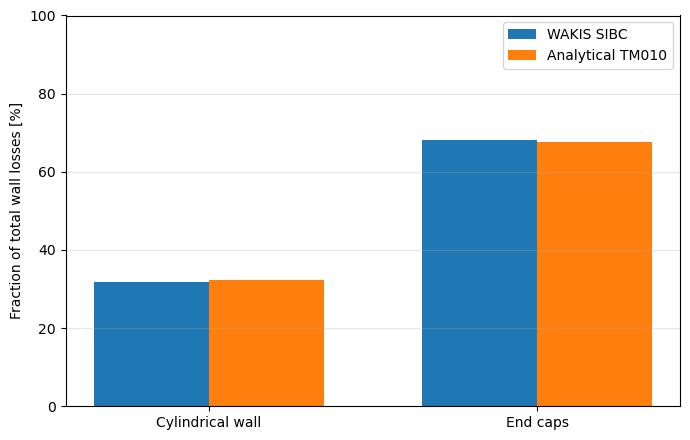

,DOF,Component,Surface,g,|curl(e)|,Loss fraction [%]
0,31249,Hx,Wall,660.119105,6800.392365,0.296499
1,109928,Hy,Wall,660.119105,6800.392365,0.296499
2,48745,Hx,Wall,660.119105,6600.698470,0.279341
3,127424,Hy,Wall,660.119105,6600.698470,0.279341
4,124508,Hy,Wall,387.306270,11958.621842,0.236744
5,45829,Hx,Wall,387.306270,11958.621842,0.236744
6,34165,Hx,Wall,387.306270,11725.448212,0.227602
7,112844,Hy,Wall,387.306270,11725.448212,0.227602
8,121592,Hy,Wall,387.306270,11529.584706,0.220061
9,42913,Hx,Wall,387.306270,11529.584706,0.220061


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# SIBC loss decomposition: cylindrical wall vs end caps
# ============================================================

SIGMA_DIAG = 1e6
omega = 2 * np.pi * f0

# ------------------------------------------------------------
# 1. Modal SIBC contribution for every magnetic DOF
# ------------------------------------------------------------

C = sibc.C_red.tocsr()
b = np.asarray(C @ e).ravel()

mnu = np.asarray(sibc.Mnu.diagonal())
Cn = np.real(np.vdot(e, pec.Meps @ e))

# Temporarily set conductivity
sigma_backup = sibc.sibc_sigma.copy()

try:
    sibc.sibc_sigma[sibc.sibc_g > 0] = SIGMA_DIAG
    D = np.asarray(sibc._build_sibc_diagonal(omega))
finally:
    sibc.sibc_sigma[:] = sigma_backup

if D.ndim == 2:
    D = np.diag(D)

delta_K_i = np.abs(b) ** 2 * mnu * (1.0 / D - 1.0)

# For exp(+j omega t), positive imaginary delta_K
# corresponds to positive damping.
loss_i = np.imag(delta_K_i)

active = np.asarray(sibc.sibc_g) > 0
loss_total = np.sum(loss_i[active])

assert loss_total > 0, "Non-positive total SIBC damping"

domega = np.sum(delta_K_i) / (2 * omega * Cn)
Q_diag = (omega + domega.real) / (2 * domega.imag)

print(f"Total active SIBC DOFs: {active.sum()}")
print(f"Total loss weight: {loss_total:.6e}")
print(f"Q from decomposition: {Q_diag:.6f}")
print(f"Q/sqrt(sigma): {Q_diag / np.sqrt(SIGMA_DIAG):.6f}")

# ------------------------------------------------------------
# 2. Map primal interface segments to magnetic DOFs
# ------------------------------------------------------------

# Classification codes:
# 0 = not classified
# 1 = cylindrical wall
# 2 = lower end cap
# 3 = upper end cap

labels = np.zeros(3 * sibc.N, dtype=np.int8)

# We use the midpoint of each STL intersection segment,
# not the FIT face center.
records = []

for component, direction in enumerate(("x", "y", "z")):
    geom = sibc.grid.interface_face_data["primal"][direction]
    shape = geom["resolved"].shape

    face_labels = np.zeros(shape, dtype=np.int8)

    for index, segment in geom["segments"].items():
        region_id = int(segment["surface_id"])

        if sibc.region_material_types[region_id] != "sibc":
            continue

        if not geom["resolved"][index]:
            continue

        p0 = np.asarray(segment["p0"], float)
        p1 = np.asarray(segment["p1"], float)
        midpoint = 0.5 * (p0 + p1)

        r = np.hypot(midpoint[0], midpoint[1])
        z = midpoint[2]

        # Identify actual INNER cavity interfaces.
        # Outer SIBC/PEC interfaces are not included.
        dr = abs(r - RADIUS)
        dz = abs(abs(z) - LENGTH / 2)

        if dr < dz:
            label = 1
        elif z < 0:
            label = 2
        else:
            label = 3

        face_labels[index] = label

    # Use the EXACT mapping used by _build_sibc_geometry().
    mapped = sibc._primal_face_array_to_dual_edge_component(
        face_labels, direction
    ).ravel(order="F")

    start = component * sibc.N
    stop = (component + 1) * sibc.N
    labels[start:stop] = mapped

# Keep only actual SIBC DOFs
labels[~active] = 0

missing = active & (labels == 0)
print(f"Unclassified active SIBC DOFs: {missing.sum()}")

if np.any(missing):
    raise RuntimeError(
        "Some active SIBC DOFs were not classified. Check face-to-DOF indexing."
    )

# ------------------------------------------------------------
# 3. Aggregate loss contributions
# ------------------------------------------------------------

groups = [
    ("Cylindrical wall", 1),
    ("Lower end cap", 2),
    ("Upper end cap", 3),
]

rows = []

for name, code in groups:
    mask = active & (labels == code)
    contribution = loss_i[mask].sum()

    rows.append(
        {
            "Surface": name,
            "SIBC DOFs": int(mask.sum()),
            "Coupled DOFs": int(
                np.count_nonzero(mask & (np.abs(b) > 1e-12 * np.max(np.abs(b))))
            ),
            "Loss weight": contribution,
            "Fraction [%]": 100 * contribution / loss_total,
        }
    )

loss_table = pd.DataFrame(rows)
display(loss_table)

# ------------------------------------------------------------
# 4. Compare against analytical TM010 fractions
# ------------------------------------------------------------

wall_numerical = loss_i[active & (labels == 1)].sum() / loss_total

caps_numerical = loss_i[active & np.isin(labels, [2, 3])].sum() / loss_total

wall_analytic = LENGTH / (RADIUS + LENGTH)
caps_analytic = RADIUS / (RADIUS + LENGTH)

print("\nLoss distribution:")
print(
    f"Cylindrical wall: numerical={100 * wall_numerical:.2f}% "
    f"analytical={100 * wall_analytic:.2f}%"
)
print(
    f"End caps:         numerical={100 * caps_numerical:.2f}% "
    f"analytical={100 * caps_analytic:.2f}%"
)

# ------------------------------------------------------------
# 5. Comparison plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4.5))

x = np.arange(2)
width = 0.35

ax.bar(
    x - width / 2,
    [100 * wall_numerical, 100 * caps_numerical],
    width,
    label="WAKIS SIBC",
)

ax.bar(
    x + width / 2,
    [100 * wall_analytic, 100 * caps_analytic],
    width,
    label="Analytical TM010",
)

ax.set_xticks(x)
ax.set_xticklabels(["Cylindrical wall", "End caps"])
ax.set_ylabel("Fraction of total wall losses [%]")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Largest individual loss contributions
# ------------------------------------------------------------

largest = np.argsort(loss_i)[::-1][:20]

top_rows = []
names = {
    0: "Unclassified",
    1: "Wall",
    2: "Lower cap",
    3: "Upper cap",
}

for i in largest:
    if not active[i]:
        continue

    top_rows.append(
        {
            "DOF": int(i),
            "Component": ("Hx", "Hy", "Hz")[i // sibc.N],
            "Surface": names[int(labels[i])],
            "g": sibc.sibc_g[i],
            "|curl(e)|": abs(b[i]),
            "Loss fraction [%]": 100 * loss_i[i] / loss_total,
        }
    )

display(pd.DataFrame(top_rows))

In [11]:
from scipy.constants import c, mu_0
from scipy.special import jn_zeros
import numpy as np

a = RADIUS
L = LENGTH

chi01 = jn_zeros(0, 1)[0]
omega_analytic = chi01 * c / a

G_analytic = omega_analytic * mu_0 * a * L / (2 * (a + L))

Rsurf_normalized = np.sqrt(omega_analytic * mu_0 / 2)

Q_over_sqrt_sigma_analytic = G_analytic / Rsurf_normalized

print(f"Geometry factor G: {G_analytic:.6f} Ohm")
print(f"Analytical Q/sqrt(sigma): {Q_over_sqrt_sigma_analytic:.6f}")
print(f"WAKIS Q/sqrt(sigma): {Q_diag / np.sqrt(SIGMA_DIAG):.6f}")
print(
    "Relative error [%]:",
    100 * (Q_diag / np.sqrt(SIGMA_DIAG) / Q_over_sqrt_sigma_analytic - 1),
)

Geometry factor G: 146.124304 Ohm
Analytical Q/sqrt(sigma): 3.146227
WAKIS Q/sqrt(sigma): 3.355433
Relative error [%]: 6.649421506653441


## 6. Interpretation and limitations

- **STL geometry:** We explicitly test the closed shell as a *metal volume*; check the WAKIS mask plot carefully because handling nested/disconnected STL surface components may vary across WAKIS/VTK versions. A passed PyVista probe is useful but not by itself proof that every FIT cell has the correct material classification.
- **PEC convergence:** A small eigenfrequency error does not guarantee convergence of magnetic fields at the conductor boundary, which determine $Q$. Repeat the SIBC sweep with at least one finer grid when evaluating quantitative agreement.
- **Exterior gap:** The finite normal/vacuum strip outside the outer shell can admit additional numerical modes; verify TM$_{010}$ mode localization with the field plots, especially if the solver reports a competing mode near the target frequency.
- **Perturbation:** The first-order SIBC treatment and analytic $Q\propto\sqrt{\sigma}$ refer to sufficiently good conductors. Do not interpret the $\sigma=10^3$ S/m case as necessarily within the strict perturbative/good-conductor limit.
- **Grid sampling:** The cell-wise $E_z$ visualization identifies the mode qualitatively; fields are FIT edge voltages and not necessarily directly colocated Cartesian samples.
- **Material semantics:** Inner and outer surfaces of the metal shell are both SIBC interfaces; only the inner mode couples appreciably to the cavity. The outer computational PEC boundary is not a substitute for treating the inner end caps as SIBC.

The notebook saves the STL and CSV results in `ideal_pillbox_results/`.